In [5]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
#Plot spectres 
from scipy import signal
from scipy import fft
import netCDF4


## Annex 3-A - CEN4 + BILAP = UBS

## Aim of Tutorial

The aim of this tutorial is to prove that the CEN4 combined with a Bi-Laplacian diffusion is equivalent to the UBS scheme.

To better understand this demonstrator you should follow Demonstrator 3 beforehand.

## Running the simulation


To run the simulation we need to run a CEN4+BILAP simulation and a UBS simulation in the case of the saltblock. You can do so yourself under the experience names ```cn_exp``` = ```CANAL_saltblock_blp_cen4``` and ```CANAL_saltblock_ubs``` __or you can execute the cell below.__

In [2]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

rm CANAL_saltblock_blp_cen4_all_grid.nc
rm CANAL_saltblock_ubs_all_grid.nc

chmod -R a+x /"$DIR"/annex1_cfg/

bash /"$DIR"/annex3_cfg/annex3A.sh "$DIR"

rm: impossible de supprimer 'CANAL_saltblock_blp_cen4_all_grid.nc': No such file or directory
rm: impossible de supprimer 'CANAL_saltblock_ubs_all_grid.nc': No such file or directory
+ set -u
+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'
+ SED_EXPR=(-e 's/rn_domszx.*=.*\!/rn_domszx        =       1000.    !/' -e 's/rn_domszy.*=.*\!/rn_domszy        =       1000.   !/' -e 's/rn_domszz.*=.*\!/rn_domszz        =       1000.  !/' -e 's/rn_dx.*=.*\!/rn_dx        =       20.     !/' -e 's/rn_dy.*=.*\!/rn_dy        =       20.  !/' -e 's/rn_dz.*=.*\!/rn_dz        =       1000.  !/' -e 's/rn_0xratio.*=.*\!/rn_0xratio      =       0.5  !/' -e 's/rn_0yratio.*=.*\!/rn_0yratio      =       0.5  !/' -e 's/nn_fcase.*=.*\!/nn_fcase  =       0  !/' -e 's/rn_ppgphi0.*=.*\!/rn

rn_salszx, rn_salszy already in the file, insertion ignored.


+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg.bak


57c57
<    cn_exp    =       'CANAL_saltblock'     !  experience name
---
>    cn_exp =  'CANAL_saltblock_blp_traadvOFF'     !  experience name
59c59
<    nn_itend  =       7680   !  last time step 
---
>    nn_itend  =       11520   !  last time step 


+ sed -i.bak -e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .true.  !/' -e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' -e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' -e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' -e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/' -e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' -e 's/nn_cen_h.*=.*\!/nn_cen_h  =       4               !/' -e 's/nn_cen_v.*=.*\!/nn_cen_v  =       4               !/' -e 's/cn_exp.*=.*'\''.*'\''/cn_exp =  '\''CANAL_compare_blp_cen4'\''      /' -e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .false. !/' -e 's/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .false. !/' -e 's/ln_traldf_blp.*=.*\!/ln_traldf_blp        =       .true. !/' /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg /Users/jbu

...

57c57
<    cn_exp =  'CANAL_compare_ubs'                 !  experience name
---
>    cn_exp =  'CANAL_compare_blp_cen4'           !  experience name
166c166
<    ln_traadv_cen        =       .false. !  2nd order centered scheme
---
>    ln_traadv_cen        =       .true.  !  2nd order centered scheme
174c174
<    ln_traadv_ubs        =       .true.  !  UBS scheme
---
>    ln_traadv_ubs        =       .false. !  UBS scheme
182c182
<    ln_traldf_OFF        =       .true. !  No explicit diffusion
---
>    ln_traldf_OFF        =       .false. !  No explicit diffusion
184c184
<    ln_traldf_blp        =       .false. !  bilaplacian operator
---
>    ln_traldf_blp        =       .true. !  bilaplacian operator


+ ./run_nemo.sh

real	0m27.127s
user	1m16.709s
sys	0m12.158s



Everything looks good



+ echo Run CANAL_compare_ubs_all_grid.nc completed


Run CANAL_compare_ubs_all_grid.nc completed


## Comparative plots

In [6]:
# Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''

In [7]:

cen4_bilap = xr.open_dataset(rep+'CANAL_compare_blp_cen4_all_grid.nc').soce.isel(deptht=0)

ubs = xr.open_dataset(rep+'CANAL_compare_ubs_all_grid.nc').soce.isel(deptht=0)

Text(0.5, 0, 't')

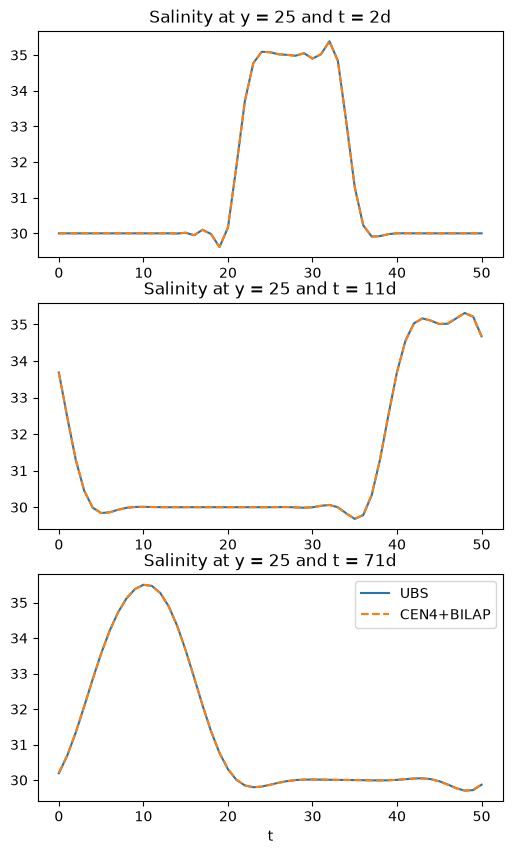

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(6,10))

ax[0].plot(np.arange(ubs.shape[2]), ubs.isel(y_grid_T = 25, time_counter = 1),  label = 'UBS')
ax[0].plot(np.arange(cen4_bilap.shape[2]), cen4_bilap.isel(y_grid_T = 25, time_counter = 1), '--', label = 'CEN4+BILAP')

ax[1].plot(np.arange(ubs.shape[2]), ubs.isel(y_grid_T = 25, time_counter = 10),  label = 'UBS')
ax[1].plot(np.arange(cen4_bilap.shape[2]), cen4_bilap.isel(y_grid_T = 25, time_counter = 10), '--', label = 'CEN4+BILAP')


ax[2].plot(np.arange(ubs.shape[2]), ubs.isel(y_grid_T = 25, time_counter = 70),  label = 'UBS')
ax[2].plot(np.arange(cen4_bilap.shape[2]), cen4_bilap.isel(y_grid_T = 25, time_counter = 70), '--', label = 'CEN4+BILAP')

plt.legend()
ax[0].set_title('Salinity at y = 25 and t = 2d')
ax[1].set_title('Salinity at y = 25 and t = 11d')
ax[2].set_title('Salinity at y = 25 and t = 71d')
ax[2].set_xlabel('t')


In [11]:
err = abs(cen4_bilap-ubs)

In [12]:
epsilon = []
for e in err : 
    epsilon.append(float((e/ubs).mean())*100)

Text(0, 0.5, '% of error')

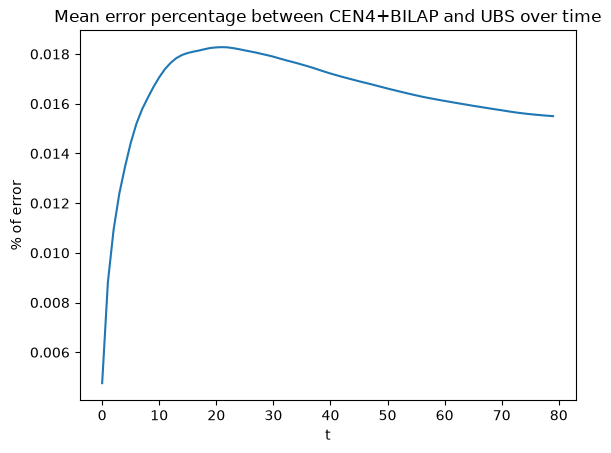

In [13]:
plt.plot(np.arange(80), epsilon)
plt.title('Mean error percentage between CEN4+BILAP and UBS over time')
plt.xlabel('t')
plt.ylabel('% of error')